##### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


##### Load CSV Files

In [2]:
customers = pd.read_csv('customers.csv', parse_dates = ['join_date'])
products = pd.read_csv('products.csv')
orders = pd.read_csv('orders.csv', parse_dates = ['order_date'])

print("Dataset loaded!") # parse_dates tells Pandas to automatically convert those columns to datetime format instead of plain strings.

Dataset loaded!


##### Inspect Each Dataset

In [3]:
print("Shape :", customers.shape)
print("\nFirst 5 rows :")
customers.head()

Shape : (1200, 6)

First 5 rows :


,customer_id,age,city,segment,join_date,gender
0,C0001,56,New York,Occasional,2020-12-21,F
1,C0002,69,Houston,Occasional,2021-11-10,F
2,C0003,46,Philadelphia,New,2022-11-19,F
3,C0004,32,San Antonio,Regular,2021-02-27,F
4,C0005,60,Chicago,Regular,2022-09-22,M


In [4]:
print("Shape :", products.shape)
print("\nFirst 5 rows :")
products.head()

Shape : (80, 5)

First 5 rows :


,product_id,category,price,rating,return_rate
0,P001,Electronics,1004.97,4.8,0.072
1,P002,Electronics,824.38,4.2,0.056
2,P003,Electronics,1060.21,3.2,0.068
3,P004,Electronics,484.86,3.2,0.051
4,P005,Electronics,346.70,4.4,0.037


In [5]:
print("Shape :", orders.shape)
print("\nFirst 5 rows :")
orders.head()

Shape : (8500, 11)

First 5 rows :


,order_id,customer_id,product_id,order_date,quantity,discount_pct,payment,status,price,category,revenue
0,O00001,C0482,P015,2024-02-03,1,10,Credit Card,Delivered,73.94,Clothing,66.55
1,O00002,C0417,P006,2023-08-09,2,5,Credit Card,Cancelled,975.36,Electronics,1853.18
2,O00003,C0525,P001,2023-07-01,1,5,Credit Card,Delivered,1004.97,Electronics,954.72
3,O00004,C0766,P020,2023-11-03,2,10,Debit Card,Delivered,140.01,Clothing,252.02
4,O00005,C0150,P036,2024-06-05,2,0,PayPal,Delivered,103.18,Home & Garden,206.36


##### Check Data Types & Missing Values

In [6]:
print("=== Customers ===")
print(customers.info())

print("\n=== Products ===")
print(products.info())

print("\n=== Orders ===")
print(orders.info())

=== Customers ===
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  1200 non-null   str           
 1   age          1200 non-null   int64         
 2   city         1200 non-null   str           
 3   segment      1200 non-null   str           
 4   join_date    1200 non-null   datetime64[us]
 5   gender       1200 non-null   str           
dtypes: datetime64[us](1), int64(1), str(4)
memory usage: 56.4 KB
None

=== Products ===
<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   product_id   80 non-null     str    
 1   category     80 non-null     str    
 2   price        80 non-null     float64
 3   rating       80 non-null     float64
 4   return_rate  80 non-null     float64
dtypes: float64(3), s

##### Check nulls specifically

In [7]:
print("Nulls in customers:\n", customers.isnull().sum())
print("\nNulls in products:\n", products.isnull().sum())
print("\nNulls in orders:\n", orders.isnull().sum())

Nulls in customers:
 customer_id    0
age            0
city           0
segment        0
join_date      0
gender         0
dtype: int64

Nulls in products:
 product_id     0
category       0
price          0
rating         0
return_rate    0
dtype: int64

Nulls in orders:
 order_id        0
customer_id     0
product_id      0
order_date      0
quantity        0
discount_pct    0
payment         0
status          0
price           0
category        0
revenue         0
dtype: int64


##### Basic Statistical Summary

In [8]:
# Numerical summary
orders.describe().round(2)

,order_date,quantity,discount_pct,price,revenue
count,8500,8500.00,8500.00,8500.00,8500.00
mean,2023-09-29 06:23:22.729411,2.02,7.15,244.07,460.22
min,2023-01-01 00:00:00,1.00,0.00,10.98,8.78
25%,2023-05-14 00:00:00,1.00,0.00,56.60,93.44
50%,2023-09-28 00:00:00,2.00,5.00,125.87,214.74
75%,2024-02-13 00:00:00,3.00,15.00,259.23,501.96
max,2024-06-29 00:00:00,4.00,20.00,1125.31,4501.24
std,NaN,1.07,7.49,296.38,685.73


In [9]:
# Categorical columns - check unique values
print("Order Status values :", orders['status'].unique())
print("Payment methods :", orders['payment'].unique())
print('Categories :', orders['category'].unique())
print('Customer segments ', customers['segment'].unique())

Order Status values : <StringArray>
['Delivered', 'Cancelled', 'Pending', 'Returned']
Length: 4, dtype: str
Payment methods : <StringArray>
['Credit Card', 'Debit Card', 'PayPal', 'UPI']
Length: 4, dtype: str
Categories : <StringArray>
['Clothing', 'Electronics', 'Home & Garden', 'Books', 'Beauty', 'Sports']
Length: 6, dtype: str
Customer segments  <StringArray>
['Occasional', 'New', 'Regular', 'Premium']
Length: 4, dtype: str


##### Quick Sanity check

In [10]:
print("Date range :", orders['order_date'].min(), "->", orders['order_date'].max())
print("Unique customers in orders :", orders['customer_id'].nunique())
print("Unique products in orders :", orders['product_id'].nunique())
print('Total Revenue (all orders) :', orders['revenue'].sum().round(2))

Date range : 2023-01-01 00:00:00 -> 2024-06-29 00:00:00
Unique customers in orders : 1179
Unique products in orders : 80
Total Revenue (all orders) : 3911905.69


#### Data Cleaning & Feature Engineering

##### Merge All 3 Tables into One Master DataFrame

In [11]:
# We use how='left' to keep all orders even if a customer/product record is somehow missing.

# Merge orders with customers
df = orders.merge(customers, how = 'left', on = 'customer_id')

# Merge with products (only need rating & return_rate - rest already in orders)
df = df.merge(products[['product_id', 'rating', 'return_rate']], on = 'product_id', how = 'left')

print("Master Dataframe shape :", df.shape)
print("Columns :", df.columns.tolist())

Master Dataframe shape : (8500, 18)
Columns : ['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment', 'status', 'price', 'category', 'revenue', 'age', 'city', 'segment', 'join_date', 'gender', 'rating', 'return_rate']


##### Remove duplicates

In [12]:
before = len(df)
df.drop_duplicates(subset = 'order_id', inplace = True)
after = len(df)

print(f"Rows before : {before}")
print(f"Rows after : {after}")
print(f"Duplicates removes : {before - after}")

Rows before : 8500
Rows after : 8500
Duplicates removes : 0


##### Fix data types

In [13]:
# check if order_date and join_date are already datetime - if not, convert
# to check datatype
df.dtypes

# To convert columns to datatime data type
df['order_date'] = pd.to_datetime(df['order_date'])
df['join_date'] = pd.to_datetime(df['join_date'])

# Convert revenue to numeric (safety check)
df['revenue'] = pd.to_numeric(df['revenue'], errors = 'coerce')

# Convert age to integer
df['age'] = df['age'].astype(int)

print(df.dtypes)

order_id                   str
customer_id                str
product_id                 str
order_date      datetime64[us]
quantity                 int64
discount_pct             int64
payment                    str
status                     str
price                  float64
category                   str
revenue                float64
age                      int64
city                       str
segment                    str
join_date       datetime64[us]
gender                     str
rating                 float64
return_rate            float64
dtype: object


##### Drop rows with critical nulls

In [14]:
df.dropna(subset = ['revenue', 'order_date'], inplace = True)
print('Nulls remaining :\n', df.isnull().sum())
print('Final shape :', df.shape)

Nulls remaining :
 order_id        0
customer_id     0
product_id      0
order_date      0
quantity        0
discount_pct    0
payment         0
status          0
price           0
category        0
revenue         0
age             0
city            0
segment         0
join_date       0
gender          0
rating          0
return_rate     0
dtype: int64
Final shape : (8500, 18)


##### Feature Engineering - create new columns

In [15]:
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.year
df['month_year'] = df['order_date'].dt.to_period('M')
df['quarter'] = df['order_date'].dt.to_period('Q')
df['weekday'] = df['order_date'].dt.day_name()

In [16]:
# Customer age group

df['age_group'] = pd.cut(
    df['age'],
    bins = [17, 25, 35, 45, 55, 70],
    labels = ['18-25', '26-35', '36-45', '46-55', '56-70']
)

In [17]:
# Net Revenue after discount
df['net_revenue'] = (df['price'] * df['quantity'] * (1 - df['discount_pct'] / 100)).round(2)

In [18]:
# Order size label
df['order_size'] = pd.cut(
    df['quantity'],
    bins = [0, 1, 2, 4],
    labels = ['Single', 'Small Bulk', 'Large Bulk']
)

print("New columns added successfully")

New columns added successfully


##### Create a "Delivered Only" subset

In [19]:
delivered = df[df['status'] == 'Delivered'].copy()

In [20]:
print(f"Total Orders          : {len(df):,}")
print(f"Delivered Orders      : {len(delivered):,}")
print(f"Cancellations         : {len(df[df['status'] == 'Cancelled']):,}")
print(f"Returned              : {len(df[df['status'] == 'Returned']):,}")

Total Orders          : 8,500
Delivered Orders      : 6,778
Cancellations         : 712
Returned              : 599


#### Exploratory Data Analysis

##### Set a simple clean style

In [21]:
sns.set_theme(style = 'whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Style set!")

Style set!


##### Order Status Count

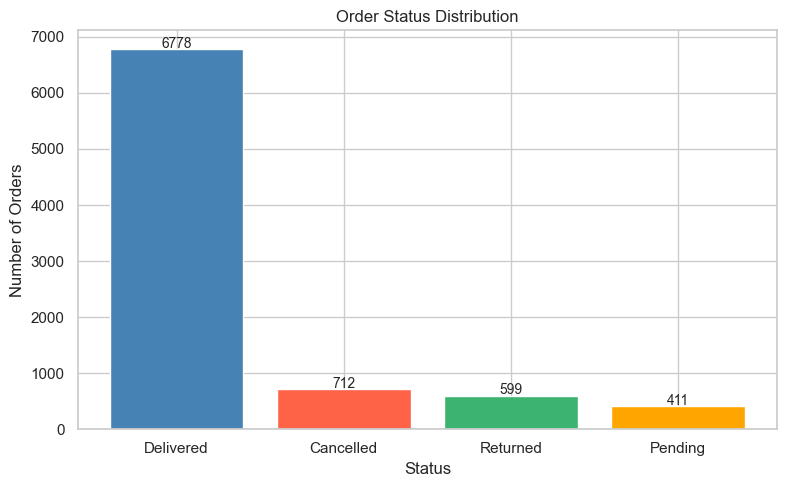

In [22]:
fig, ax = plt.subplots()

status_counts = df['status'].value_counts()

ax.bar(status_counts.index, status_counts.values, color = ['steelblue', 'tomato', 'mediumseagreen', 'orange'])

ax.set_title('Order Status Distribution')
ax.set_xlabel('Status')
ax.set_ylabel('Number of Orders')

# Add count labels on top
for i, v in enumerate (status_counts.values) :
    ax.text(i, v + 30, str(v), ha = 'center', fontsize = 10)
plt.tight_layout()
plt.show()

##### Revenue by Category

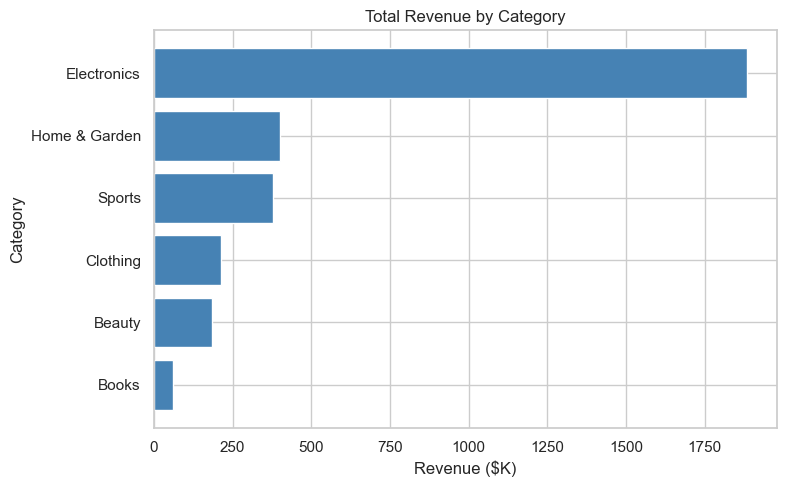

In [23]:
fig, ax = plt.subplots()

cat_rev = delivered.groupby('category')['revenue'].sum().sort_values()
ax.barh(cat_rev.index, cat_rev.values / 1000, color = 'steelblue')

ax.set_title('Total Revenue by Category')
ax.set_xlabel('Revenue ($K)')
ax.set_ylabel('Category')

plt.tight_layout()
plt.show()

##### Number of Orders per category

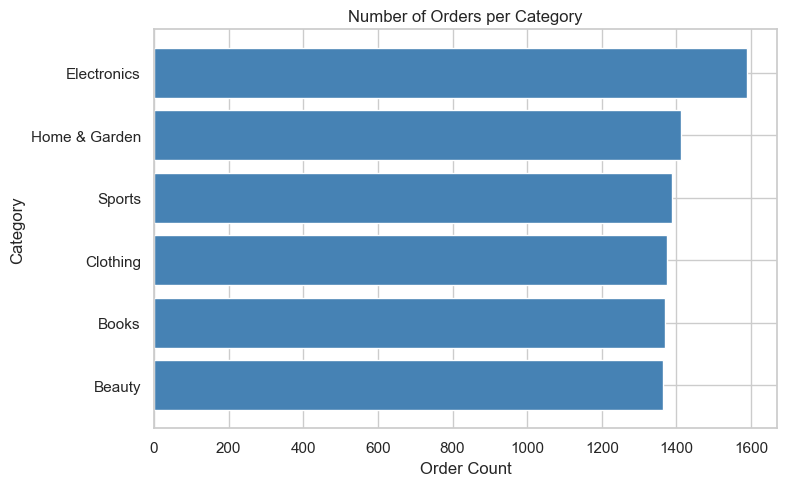

In [24]:
fig, ax = plt.subplots()

cat_orders = df.groupby('category')['order_id'].count().sort_values()
ax.barh(cat_orders.index, cat_orders.values, color = 'steelblue')

ax.set_title('Number of Orders per Category')
ax.set_xlabel('Order Count')
ax.set_ylabel('Category')

plt.tight_layout()
plt.show()

##### Revenue by Customer Segment

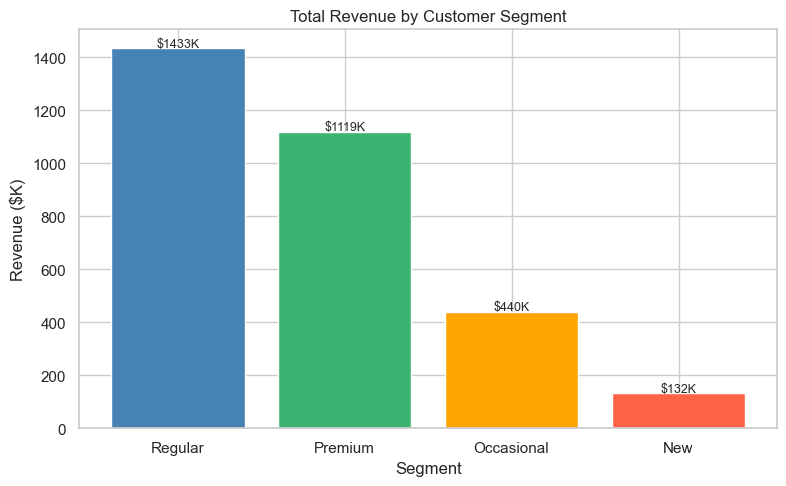

In [25]:
fig, ax = plt.subplots()

seg_rev = delivered.groupby('segment')['revenue'].sum().sort_values(ascending = False)
ax.bar(seg_rev.index, seg_rev.values / 1000, color = ['steelblue', 'mediumseagreen', 'orange', 'tomato'])

ax.set_title('Total Revenue by Customer Segment')
ax.set_xlabel('Segment')
ax.set_ylabel('Revenue ($K)')

for i,v in enumerate (seg_rev.values) :
    ax.text(i, v / 1000 + 5, f"${v/1000:.0f}K", ha = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

##### Orders by Day of Week

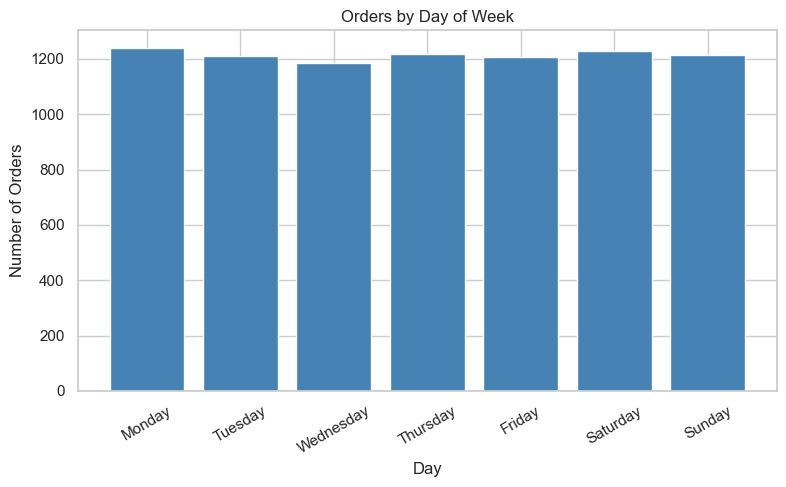

In [26]:
fig, ax = plt.subplots()

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_cnt = df['weekday'].value_counts().reindex(day_order)

ax.bar(day_order, weekday_cnt.values, color = 'steelblue')
ax.set_title('Orders by Day of Week')
ax.set_xlabel('Day')
ax.set_ylabel('Number of Orders')
ax.tick_params(axis = 'x', rotation = 30)

plt.tight_layout()
plt.show()

##### Revenue by Age Group

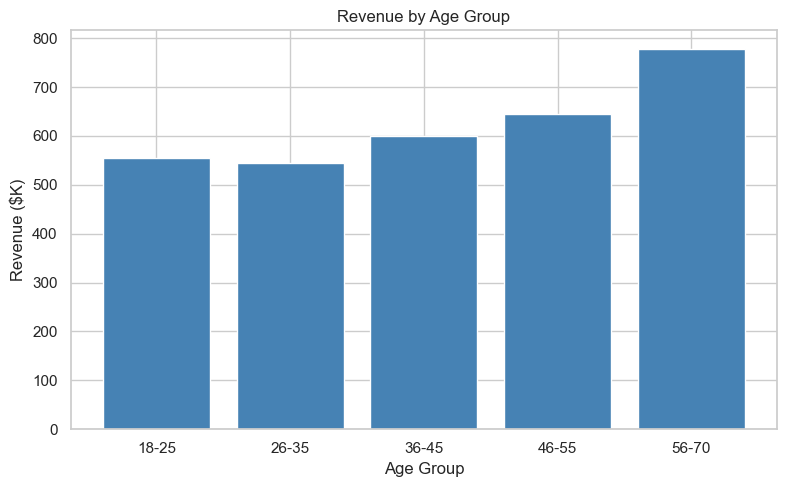

In [27]:
fig, ax = plt.subplots()

age_rev = delivered.groupby('age_group', observed = True)['revenue'].sum()
ax.bar(age_rev.index.astype(str), age_rev.values / 1000, color = 'steelblue')

ax.set_title('Revenue by Age Group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Revenue ($K)')

plt.tight_layout()
plt.show()

##### Payment method counts

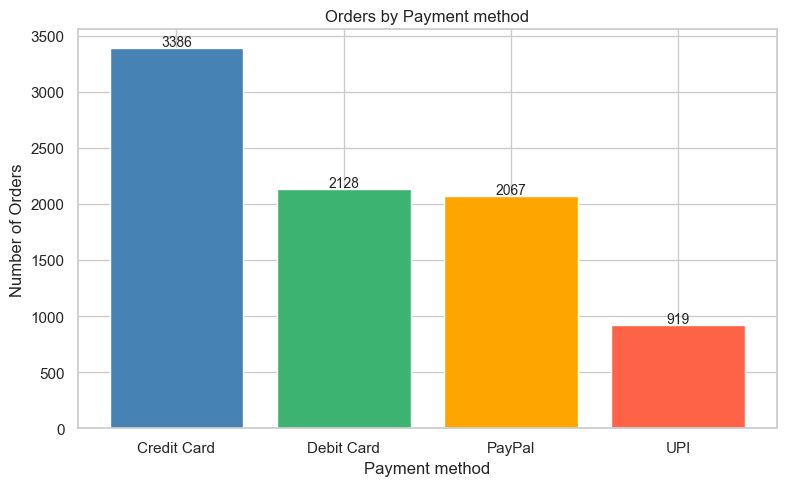

In [28]:
fig, ax = plt.subplots()

pay = df['payment'].value_counts()

ax.bar(pay.index, pay.values, color = ['steelblue', 'mediumseagreen', 'orange', 'tomato'])

ax.set_title('Orders by Payment method')
ax.set_xlabel('Payment method')
ax.set_ylabel('Number of Orders')

for i, v in enumerate (pay.values) :
    ax.text(i, v + 20, str(v), ha = 'center', fontsize = 10)

plt.tight_layout()
plt.show()

In [29]:
print("=== KEY EDA STATS ===\n")

print("Top Category by Revenue:")
print(delivered.groupby('category')['revenue'].sum().sort_values(ascending=False).head(3))

print("\nAvg Order Value by Segment:")
print(delivered.groupby('segment')['revenue'].mean().round(2).sort_values(ascending=False))

print("\nCancellation Rate by Category:")
cancel = (df.groupby('category')
          .apply(lambda x: (x['status'] == 'Cancelled').sum() / len(x) * 100)
          .round(2).sort_values(ascending=False))
print(cancel)

=== KEY EDA STATS ===

Top Category by Revenue:
category
Electronics      1886043.38
Home & Garden     399782.13
Sports            377805.52
Name: revenue, dtype: float64

Avg Order Value by Segment:
segment
New           480.52
Occasional    464.59
Regular       463.79
Premium       453.27
Name: revenue, dtype: float64

Cancellation Rate by Category:
category
Clothing         9.02
Beauty           8.72
Books            8.55
Home & Garden    8.28
Electronics      8.11
Sports           7.63
dtype: float64


#### Revenue Trend Analysis

##### Prepare Monthly Revenue Data

In [30]:
# Group delivered orders by month

monthly = delivered.groupby('month_year').agg(
    revenue = ('revenue', 'sum'),
    orders = ('order_id', 'count'),
    customers = ('customer_id', 'nunique')
).reset_index()

# Convert period to string for plotting
monthly['month_str'] = monthly['month_year'].astype(str)

# Calculate Average Order Value (AOV)
monthly['aov'] = (monthly['revenue'] / monthly['orders']).round(2)

# Calculate Month-over-Month growth %
monthly['mom_growth'] = monthly['revenue'].pct_change() * 100

print(monthly.head())
print("\nShape:", monthly.shape)

  month_year    revenue  orders  customers month_str     aov  mom_growth
0    2023-01  179989.60     407        329   2023-01  442.23         NaN
1    2023-02  142630.96     351        289   2023-02  406.36  -20.755999
2    2023-03  184605.43     392        334   2023-03  470.93   29.428723
3    2023-04  172399.52     367        307   2023-04  469.75   -6.611891
4    2023-05  173502.05     359        293   2023-05  483.29    0.639520

Shape: (18, 7)


##### Monthly Revenue Trend

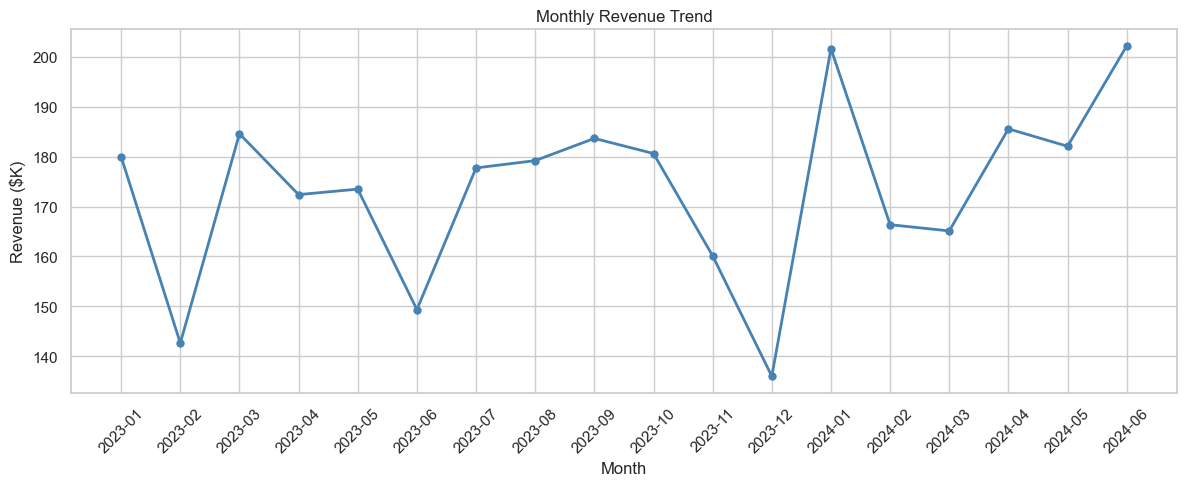

In [31]:
fig, ax = plt.subplots(figsize = (12, 5))

ax.plot(monthly['month_str'], monthly['revenue'] / 1000, marker = 'o', color = 'steelblue', linewidth = 2, markersize = 5)

ax.set_title('Monthly Revenue Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue ($K)')
ax.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()

# What to observe: Is revenue growing over time? Any dips or seasonal spikes?

##### Monthly Revenue with 3-Month Moving Average

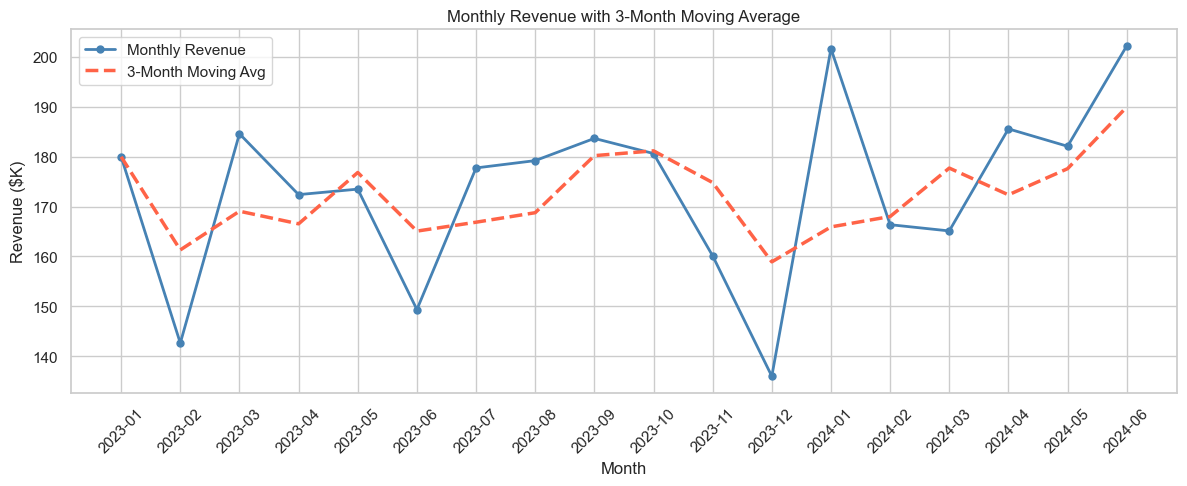

In [32]:
# Calculate 3-month rolling average

monthly['revenue_3ma'] = monthly['revenue'].rolling(window = 3, min_periods = 1).mean()

fig, ax = plt.subplots(figsize = (12, 5))

ax.plot(monthly['month_str'], monthly['revenue'] / 1000, marker = 'o', color = 'steelblue', linewidth = 2, markersize = 5, label = 'Monthly Revenue')

ax.plot(monthly['month_str'], monthly['revenue_3ma'] / 1000, color = 'tomato', linewidth = 2.5, linestyle = '--', label = '3-Month Moving Avg')

ax.set_title('Monthly Revenue with 3-Month Moving Average')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue ($K)')
ax.tick_params(axis = 'x', rotation = 45)
ax.legend()

plt.tight_layout()
plt.show()

# Moving average smooths out noise and shows the real underlying trend. A 3-month window is standard for monthly data.

##### Monthly Order Count Trend

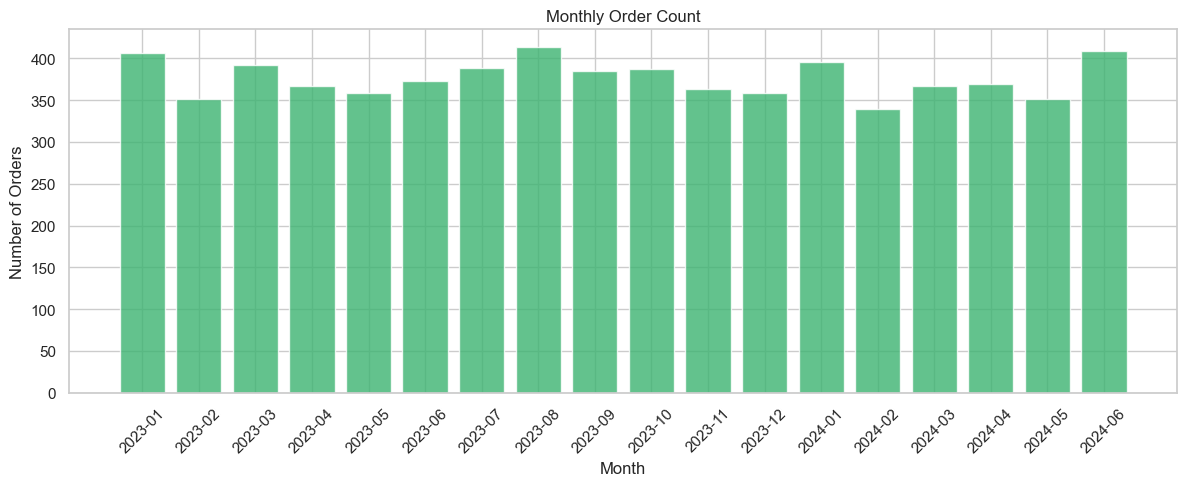

In [33]:
fig, ax = plt.subplots(figsize = (12, 5))
ax.bar(monthly['month_str'], monthly['orders'], color = 'mediumseagreen', alpha = 0.8)

ax.set_title('Monthly Order Count')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Orders')
ax.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()

# What to observe: Are order volumes growing in line with revenue? If revenue grows but orders don't — customers are spending more per order.

##### Average order value (AOV) over time

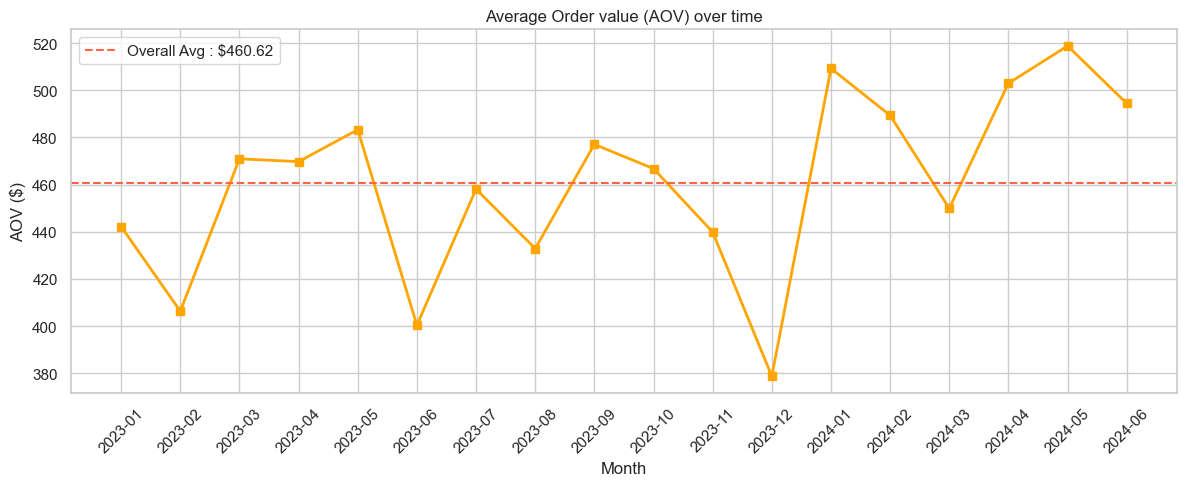

In [34]:
fig, ax = plt.subplots(figsize = (12, 5))

ax.plot(monthly['month_str'], monthly['aov'], marker = 's', color = 'orange', linewidth = 2, markersize = 6)

ax.set_title('Average Order value (AOV) over time')
ax.set_xlabel('Month')
ax.set_ylabel('AOV ($)')
ax.tick_params(axis = 'x', rotation = 45)

# Add a horizontal average line
avg_aov = monthly['aov'].mean()
ax.axhline(avg_aov, color = 'tomato', linestyle = '--', linewidth = 1.5, label = f'Overall Avg : ${avg_aov:.2f}')
ax.legend()

plt.tight_layout()
plt.show()

# AOV = Total Revenue / Number of Orders. A rising AOV means customers are buying more expensive items or adding more to their cart.

##### Month over month Revenue growth %

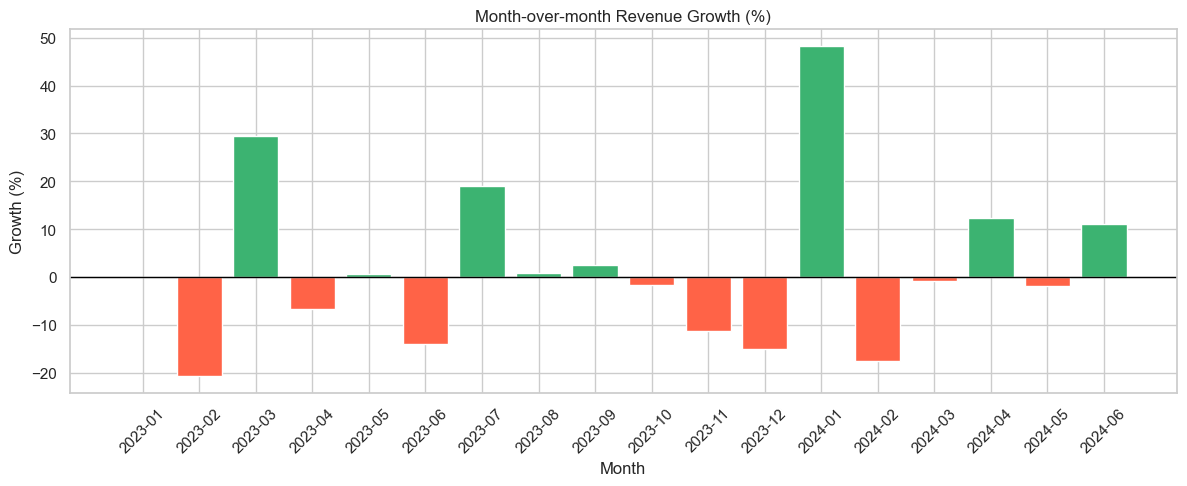

In [35]:
fig, ax = plt.subplots(figsize = (12, 5))

# color bars green for positive growth, red for negative
colors = ['mediumseagreen' if v >= 0 else 'tomato'
         for v in monthly['mom_growth'].fillna(0)]

ax.bar(monthly['month_str'], monthly['mom_growth'].fillna(0), color = colors)

ax.axhline(0, color = 'black', linewidth = 1)
ax.set_title('Month-over-month Revenue Growth (%)')
ax.set_xlabel('Month')
ax.set_ylabel('Growth (%)')
ax.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()

# What to observe: Which months saw a drop? Which had the biggest jump? This is great for identifying seasonal patterns.

##### Quarterly Revenue Comparison

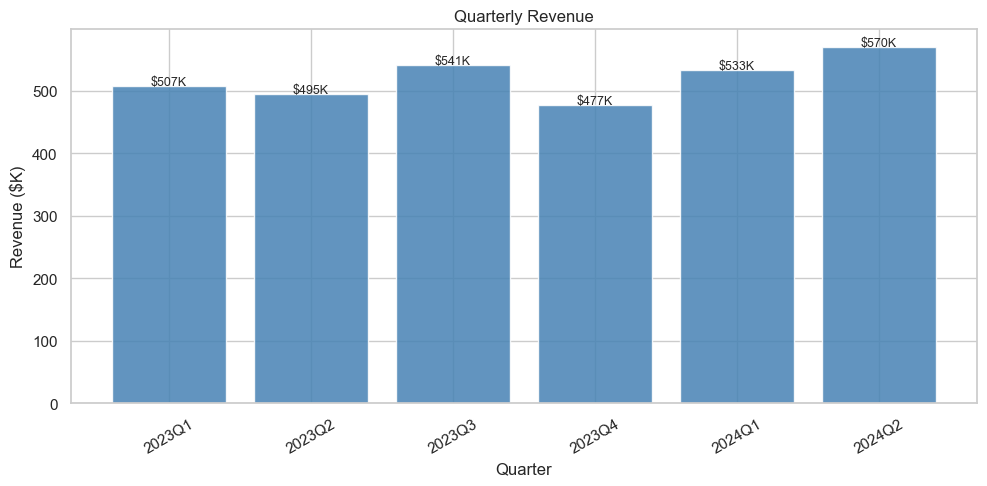

In [36]:
fig, ax = plt.subplots(figsize = (10, 5))

quarterly = delivered.groupby('quarter')['revenue'].sum().reset_index()
quarterly['quarter_str'] = quarterly['quarter'].astype(str)

ax.bar(quarterly['quarter_str'], quarterly['revenue'] / 1000, color = 'steelblue', alpha = 0.85)

ax.set_title('Quarterly Revenue')
ax.set_xlabel('Quarter')
ax.set_ylabel('Revenue ($K)')
ax.tick_params(axis = 'x', rotation = 30)

# Add value labels
for i, v in enumerate(quarterly['revenue'].values) :
    ax.text(i, v/1000 + 2, f'${v/1000:.0f}K', ha = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

# Quarterly view is what business stakeholders look at most — always include it in a portfolio project.

##### Active Customers per Month

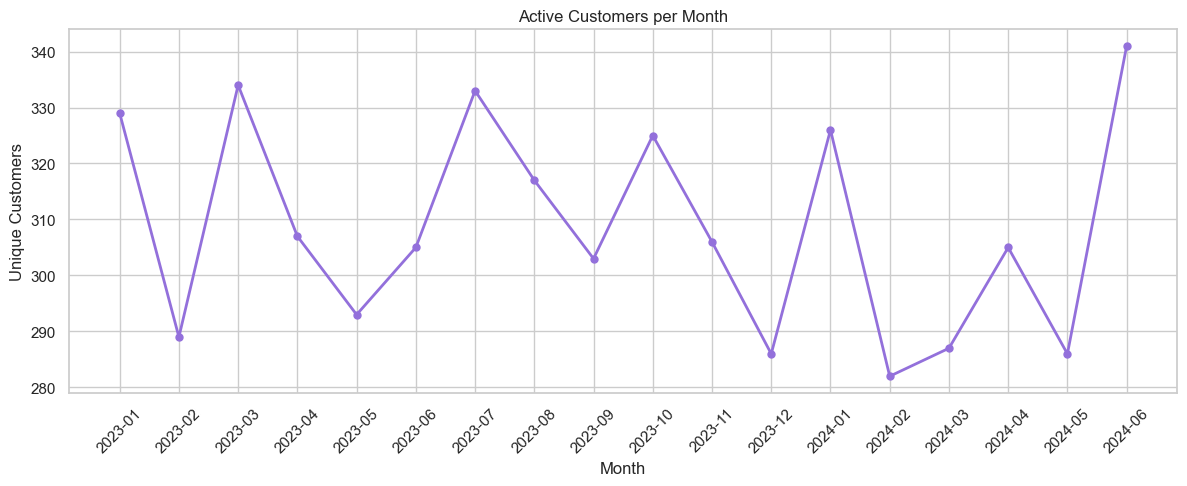

In [37]:
fig, ax = plt.subplots(figsize = (12, 5))

ax.plot(monthly['month_str'], monthly['customers'], marker = 'o', color = 'mediumpurple', linewidth = 2, markersize = 5)

ax.set_title('Active Customers per Month')
ax.set_xlabel('Month')
ax.set_ylabel('Unique Customers')
ax.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()

# Active customer trend tells you if you're growing your customer base or relying on repeat buyers.

In [38]:
print("=== REVENUE TREND SUMMARY ===\n")

print(f"Best Month      : {monthly.loc[monthly['revenue'].idxmax(), 'month_str']}"
      f"  →  ${monthly['revenue'].max()/1000:.1f}K")

print(f"Worst Month     : {monthly.loc[monthly['revenue'].idxmin(), 'month_str']}"
      f"  →  ${monthly['revenue'].min()/1000:.1f}K")

print(f"Avg Monthly Rev : ${monthly['revenue'].mean()/1000:.1f}K")

print(f"Avg AOV         : ${monthly['aov'].mean():.2f}")

print(f"Avg MoM Growth  : {monthly['mom_growth'].mean():.1f}%")

print(f"Best Growth Month : {monthly.loc[monthly['mom_growth'].idxmax(), 'month_str']}"
      f"  →  {monthly['mom_growth'].max():.1f}%")

=== REVENUE TREND SUMMARY ===

Best Month      : 2024-06  →  $202.2K
Worst Month     : 2023-12  →  $136.0K
Avg Monthly Rev : $173.5K
Avg AOV         : $460.62
Avg MoM Growth  : 2.0%
Best Growth Month : 2024-01  →  48.3%


#### Cohort Retention Analysis

##### Find each customer's First Purchase Month

In [39]:
# Get the first order date for each customer

cohort_df = delivered[['customer_id', 'order_date']].copy()

# Find the first purchase month for each customer (their cohort)
cohort_df['cohort_month'] = (cohort_df.groupby('customer_id')['order_date'].transform('min').dt.to_period('M'))

# Get the month of each individual order
cohort_df['order_month'] = cohort_df['order_date'].dt.to_period('M')
print(cohort_df.head(10))

# transform('min') returns the earliest order date for each customer and maps it back to every row of that customer. Very useful Pandas trick!

   customer_id order_date cohort_month order_month
0        C0482 2024-02-03      2023-01     2024-02
2        C0525 2023-07-01      2023-01     2023-07
3        C0766 2023-11-03      2023-01     2023-11
4        C0150 2024-06-05      2023-05     2024-06
5        C0339 2024-01-31      2023-05     2024-01
6        C0620 2023-01-04      2023-01     2023-01
7        C0389 2023-10-08      2023-01     2023-10
8        C1192 2023-08-03      2023-01     2023-08
9        C0521 2024-02-24      2023-03     2024-02
10       C1047 2023-04-11      2023-04     2023-04


##### Calculated Period Number

In [40]:
# Period number = how many months after first purchase this order happened

cohort_df['period_number'] = (
    cohort_df['order_month'] - cohort_df['cohort_month']
).apply(lambda x : x.n)

print("\nSample with period numbers:")
print(cohort_df.head(10))

print("\nPeriod number range:", cohort_df['period_number'].min(), "→", cohort_df['period_number'].max())

# Period 0 = the month the customer first bought. Period 1 = one month later, and so on.


Sample with period numbers:
   customer_id order_date cohort_month order_month  period_number
0        C0482 2024-02-03      2023-01     2024-02             13
2        C0525 2023-07-01      2023-01     2023-07              6
3        C0766 2023-11-03      2023-01     2023-11             10
4        C0150 2024-06-05      2023-05     2024-06             13
5        C0339 2024-01-31      2023-05     2024-01              8
6        C0620 2023-01-04      2023-01     2023-01              0
7        C0389 2023-10-08      2023-01     2023-10              9
8        C1192 2023-08-03      2023-01     2023-08              7
9        C0521 2024-02-24      2023-03     2024-02             11
10       C1047 2023-04-11      2023-04     2023-04              0

Period number range: 0 → 17


##### Build the Cohort Table (Customer Counts)

In [41]:
# Count unique customers per cohort month and period number
cohort_counts = (cohort_df.groupby(['cohort_month', 'period_number'])['customer_id'].nunique().reset_index())

# Pivot into a table format
cohort_pivot = cohort_counts.pivot(
    index = 'cohort_month',
    columns = 'period_number',
    values = 'customer_id'
)

print("Cohort Count table :")
print(cohort_pivot.iloc[:6, :7])

# Rows = cohort month. Columns = period number. Values = number of active customers.

Cohort Count table :
period_number      0      1      2      3     4      5      6
cohort_month                                                 
2023-01        329.0  111.0  122.0  112.0  99.0  107.0  106.0
2023-02        178.0   60.0   52.0   52.0  58.0   59.0   59.0
2023-03        152.0   43.0   45.0   31.0  40.0   39.0   31.0
2023-04        100.0   22.0   25.0   28.0  29.0   28.0   29.0
2023-05         75.0   15.0   24.0   25.0  15.0   19.0   19.0
2023-06         69.0   23.0   15.0   17.0  13.0   18.0   11.0


#### Convert to Retention Percentage

In [42]:
# Divide every row by the Period 0 value (first month count)

cohort_pct = cohort_pivot.divide(cohort_pivot[0], axis = 0) * 100
cohort_pct = cohort_pct.round(1)

print("Cohort Retention % Table:")
print(cohort_pct.iloc[:6,:7])

# Period 0 is always 100% because we’re dividing each row by itself. Every other value shows what % of those original customers came back.

Cohort Retention % Table:
period_number      0     1     2     3     4     5     6
cohort_month                                            
2023-01        100.0  33.7  37.1  34.0  30.1  32.5  32.2
2023-02        100.0  33.7  29.2  29.2  32.6  33.1  33.1
2023-03        100.0  28.3  29.6  20.4  26.3  25.7  20.4
2023-04        100.0  22.0  25.0  28.0  29.0  28.0  29.0
2023-05        100.0  20.0  32.0  33.3  20.0  25.3  25.3
2023-06        100.0  33.3  21.7  24.6  18.8  26.1  15.9


##### Cohort Retention Heatmap (%)

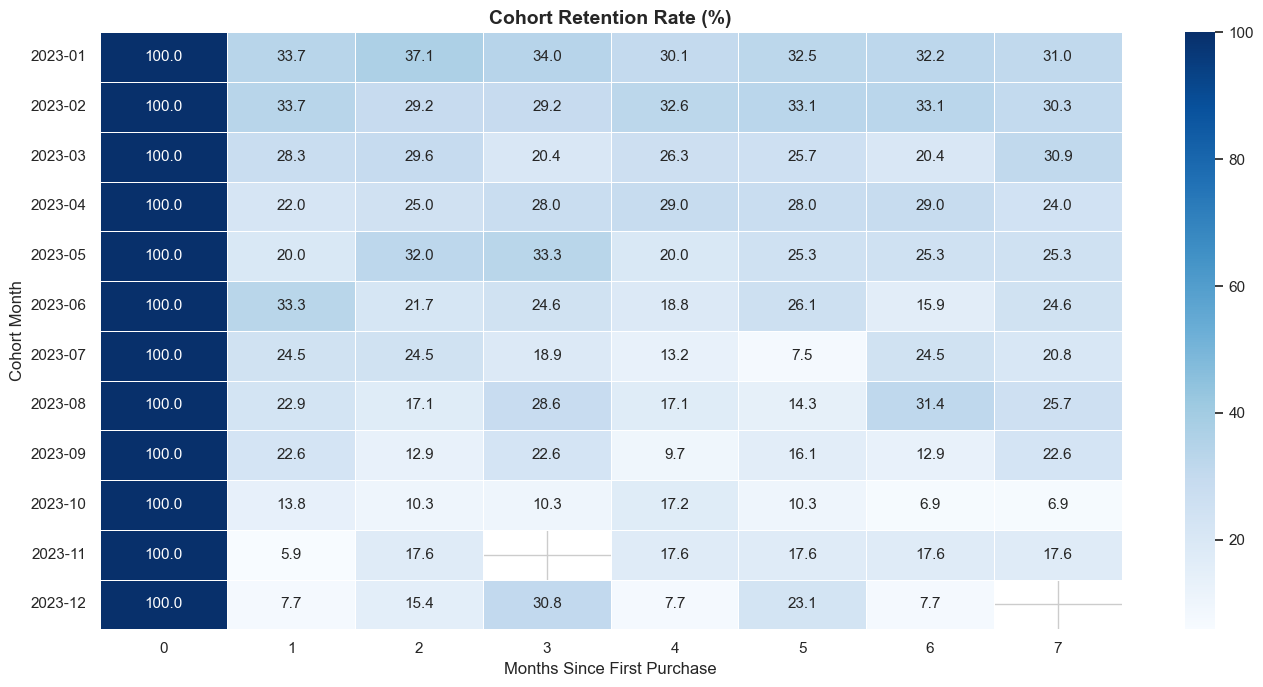

In [43]:
fig, ax = plt.subplots(figsize = (14, 7))

sns.heatmap(
    cohort_pct.iloc[:12, :8],    # First 12 cohorts, first 8 periods
    annot = True,                # show numbers inside cells
    fmt = '.1f',                 # 1 decimal place
    cmap = 'Blues',              # darker = higher retention
    linewidth = 0.5,
    linecolor = 'white',
    ax = ax
)

ax.set_title('Cohort Retention Rate (%)', fontsize = 14, fontweight = 'bold')
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Cohort Month')
ax.tick_params(axis = 'y', rotation = 0)

plt.tight_layout()
plt.show()

# How to read it: Look across any row - the faster the color fades, the faster customers are dropping off. Look down any column - if numbers are going up, retention is improving over time.

##### Cohort Size (How Many New Customers per Month)

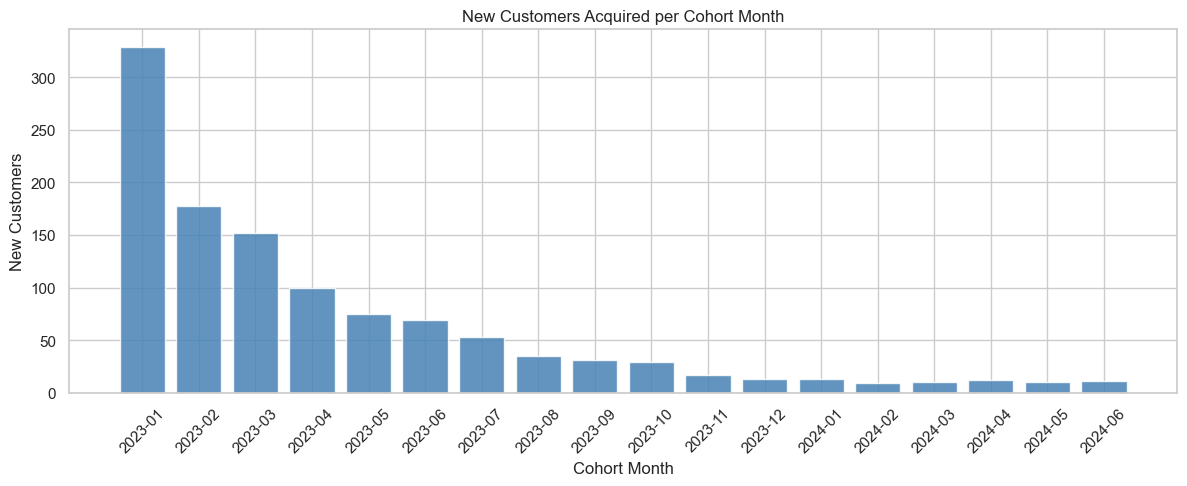

In [44]:
fig, ax = plt.subplots(figsize = (12, 5))

cohort_sizes = cohort_pivot[0]           # Period 0 = new customers that month
ax.bar(cohort_sizes.index.astype(str), cohort_sizes.values, color = 'steelblue', alpha = 0.85)

ax.set_title('New Customers Acquired per Cohort Month')
ax.set_xlabel('Cohort Month')
ax.set_ylabel('New Customers')
ax.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()

# What to observe: Are we acquiring more new customers over time or is it flat?

##### Retention Curve (Average Across All Cohorts)

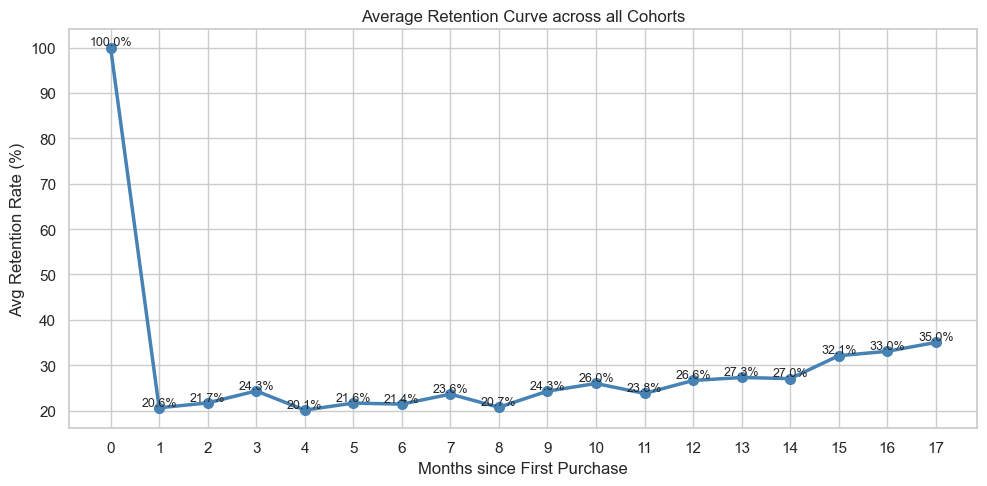

In [45]:
fig, ax = plt.subplots(figsize = (10, 5))

# Average retention % across all cohorts for each period
avg_retention = cohort_pct.mean()

ax.plot(avg_retention.index, avg_retention.values, marker = 'o', color = 'steelblue', linewidth = 2.5, markersize = 7)

ax.set_title('Average Retention Curve across all Cohorts')
ax.set_xlabel('Months since First Purchase')
ax.set_ylabel('Avg Retention Rate (%)')

# Add value labels on each point
for x,y in zip(avg_retention.index, avg_retention.values) :
    ax.text(x, y + 0.5, f'{y:.1f}%', ha = 'center', fontsize = 9)

ax.set_xticks(avg_retention.index)
plt.tight_layout()
plt.show()

# This is the most important chart. It shows the average customer lifecycle. The steeper the drop between Period 0 and Period 1 — the bigger the retention problem.

##### Retention at Month 1 by Cohort

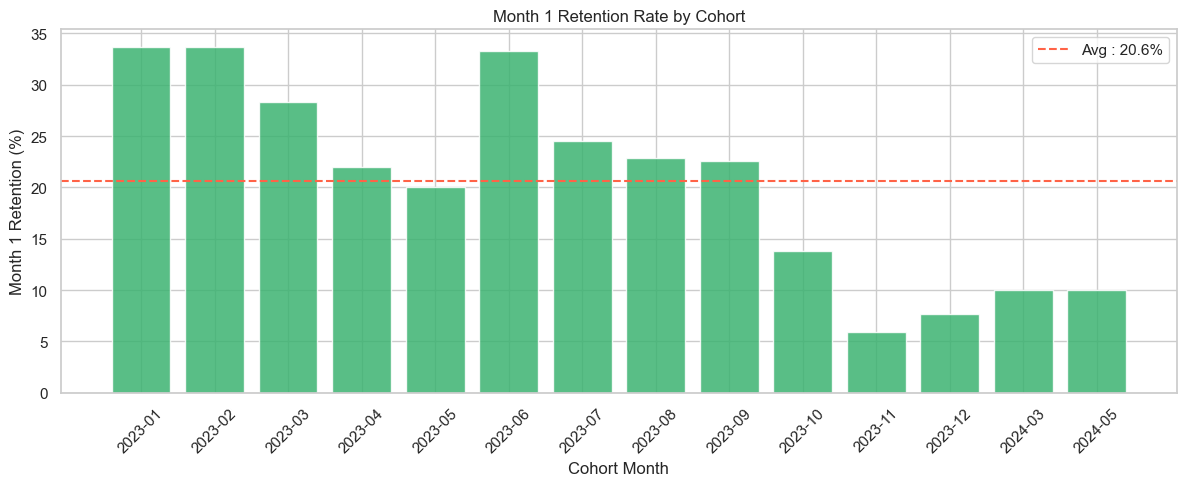

In [46]:
fig, ax = plt.subplots(figsize = (12, 5))

# Month 1 retention for each cohort
month1_retention = cohort_pct[1].dropna()

ax.bar(month1_retention.index.astype(str), month1_retention.values, color = 'mediumseagreen', alpha = 0.85)

# Add average line
avg_m1 = month1_retention.mean()
ax.axhline(avg_m1, color = 'tomato', linestyle = '--', linewidth = 1.5, label = f'Avg : {avg_m1:.1f}%')

ax.set_title('Month 1 Retention Rate by Cohort')
ax.set_xlabel('Cohort Month')
ax.set_ylabel('Month 1 Retention (%)')
ax.tick_params(axis = 'x', rotation = 45)
ax.legend()

plt.tight_layout()
plt.show()

# Month 1 retention is the most critical metric. If a customer doesn’t come back after their first purchase, chances are they never will.

#### Key Retention Stats

In [47]:
print("=== COHORT RETENTION SUMMARY ===\n")

print(f"Avg Month-1 Retention : {cohort_pct[1].mean():.1f}%")
print(f"Avg Month-2 Retention : {cohort_pct[2].mean():.1f}%")
print(f"Avg Month-3 Retention : {cohort_pct[3].mean():.1f}%")

print(f"\nBest Cohort (Month-1)  : {cohort_pct[1].idxmax()} "
      f"→ {cohort_pct[1].max():.1f}%")

print(f"Worst Cohort (Month-1) : {cohort_pct[1].idxmin()} "
      f"→ {cohort_pct[1].min():.1f}%")

print(f"\nTotal Cohorts Analysed : {len(cohort_pivot)}")
print(f"Avg Cohort Size        : {cohort_pivot[0].mean():.0f} customers")

=== COHORT RETENTION SUMMARY ===

Avg Month-1 Retention : 20.6%
Avg Month-2 Retention : 21.7%
Avg Month-3 Retention : 24.3%

Best Cohort (Month-1)  : 2023-01 → 33.7%
Worst Cohort (Month-1) : 2023-11 → 5.9%

Total Cohorts Analysed : 18
Avg Cohort Size        : 64 customers


#### Product Performance Analysis

##### Build Product Performance Table

In [48]:
# Aggregate product level metrics from delivered orders

prod_pref = delivered.groupby(['product_id', 'category']).agg(
    total_revenue = ('revenue', 'sum'),
    total_orders = ('order_id', 'count'),
    avg_discount = ('discount_pct', 'mean'),
    total_quantity = ('quantity', 'sum')
).reset_index()

# Bring in rating and return_rate from products table
prod_pref = prod_pref.merge(
    products[['product_id', 'price', 'rating', 'return_rate']], on = 'product_id', how = 'left'
)

# revenue per order for each product
prod_pref['revenue_per_order'] = (prod_pref['total_revenue'] / prod_pref['total_orders']).round(2)

# Round columns
prod_pref['avg_discount'] = prod_pref['avg_discount'].round(2)
prod_pref['total_revenue'] = prod_pref['total_revenue'].round(2)

print('Product Performance Table Shape :', prod_pref.shape)
print(prod_pref.head())

Product Performance Table Shape : (80, 10)
  product_id     category  total_revenue  total_orders  avg_discount  \
0       P001  Electronics      167025.97            81          7.10   
1       P002  Electronics      125182.07            78          7.24   
2       P003  Electronics      183469.39            95          6.05   
3       P004  Electronics       74401.75            75          7.20   
4       P005  Electronics       74037.76           120          6.71   

   total_quantity    price  rating  return_rate  revenue_per_order  
0             179  1004.97     4.8        0.072            2062.05  
1             165   824.38     4.2        0.056            1604.90  
2             184  1060.21     3.2        0.068            1931.26  
3             165   484.86     3.2        0.051             992.02  
4             229   346.70     4.4        0.037             616.98  


##### Top 10 Products by Revenue

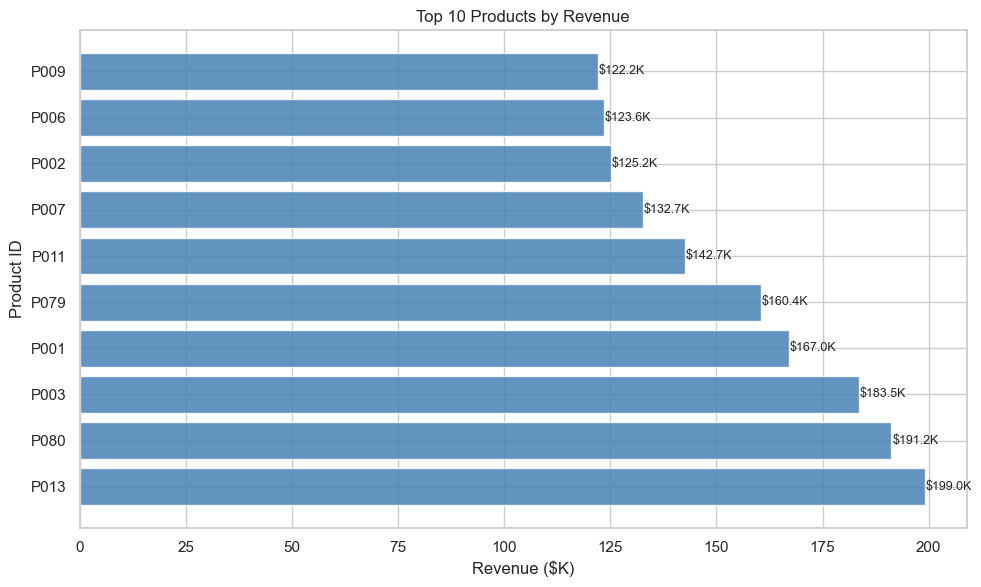

In [49]:
fig, ax = plt.subplots(figsize = (10, 6))

top10_rev = prod_pref.nlargest(10, 'total_revenue')

ax.barh(top10_rev['product_id'], top10_rev['total_revenue'] / 1000, color = 'steelblue', alpha = 0.85)
ax.set_title('Top 10 Products by Revenue')
ax.set_xlabel('Revenue ($K)')
ax.set_ylabel('Product ID')

# Add value labels
for i, v in enumerate (top10_rev['total_revenue'].values) :
    ax.text(v/1000 + 0.2, i, f'${v/1000:.1f}K', va = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

# What to observe: A small number of products usually drive the majority of revenue — this is the classic 80/20 rule (Pareto Principle).

##### Bottom 10 Products by Revenue

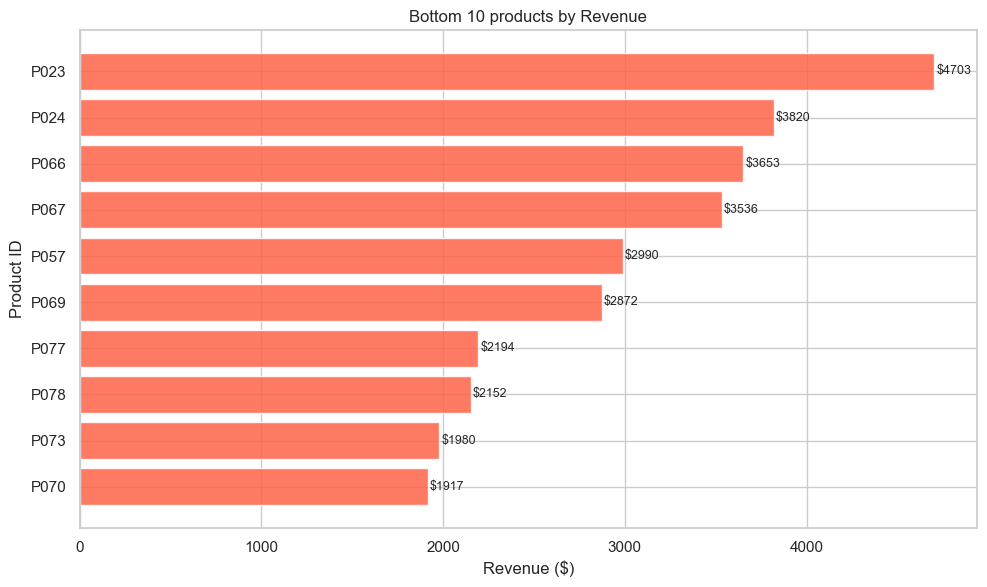

In [50]:
fig, ax = plt.subplots(figsize = (10, 6))

bottom10_rev = prod_pref.nsmallest(10, 'total_revenue')

ax.barh(bottom10_rev['product_id'], bottom10_rev['total_revenue'], color = 'tomato', alpha = 0.85)

ax.set_title('Bottom 10 products by Revenue')
ax.set_xlabel('Revenue ($)')
ax.set_ylabel('Product ID')

for i, v in enumerate (bottom10_rev['total_revenue'].values) :
    ax.text(v + 10, i, f'${v:.0f}', va = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

# Business insight: These products may need to be discounted, promoted, or discontinued.

##### Revenue by Category (Box Plot)

C:\Users\shubhamtyagi\AppData\Local\Temp\ipykernel_27248\2527454953.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


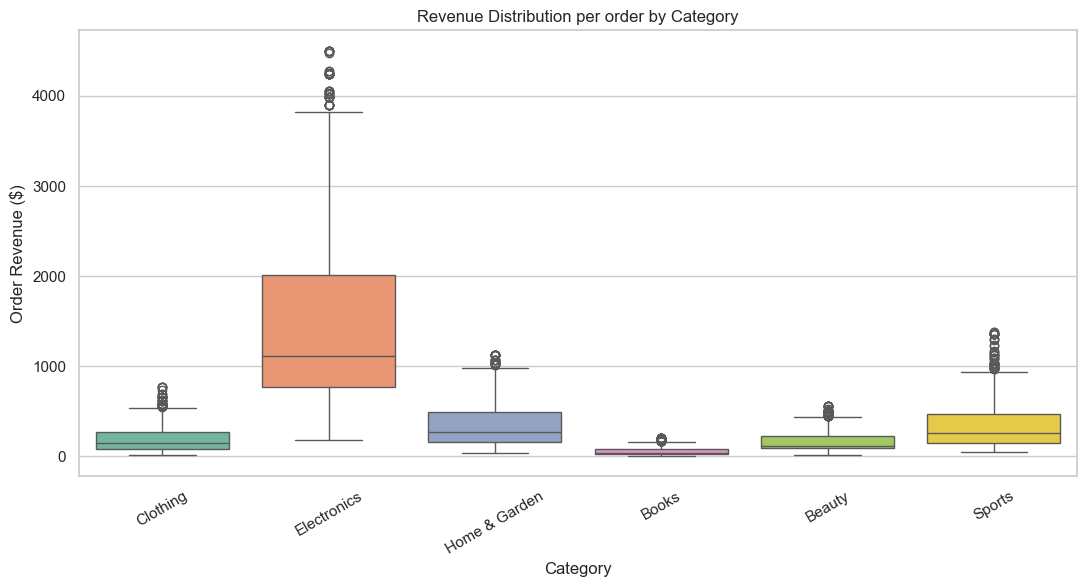

In [51]:
fig, ax = plt.subplots(figsize = (11,6))

# Box plot shows distribution of revenue per order within each category

sns.boxplot(
    data = delivered,
    x = 'category',
    y = 'revenue',
    palette = 'Set2',
    ax = ax
)

ax.set_title('Revenue Distribution per order by Category')
ax.set_xlabel('Category')
ax.set_ylabel('Order Revenue ($)')
ax.tick_params(axis = 'x', rotation = 30)

plt.tight_layout()
plt.show()

# Why a box plot? It shows min, max, median and outliers all at once. Electronics will likely show a wider spread because prices vary a lot.

##### Average Discount by Category

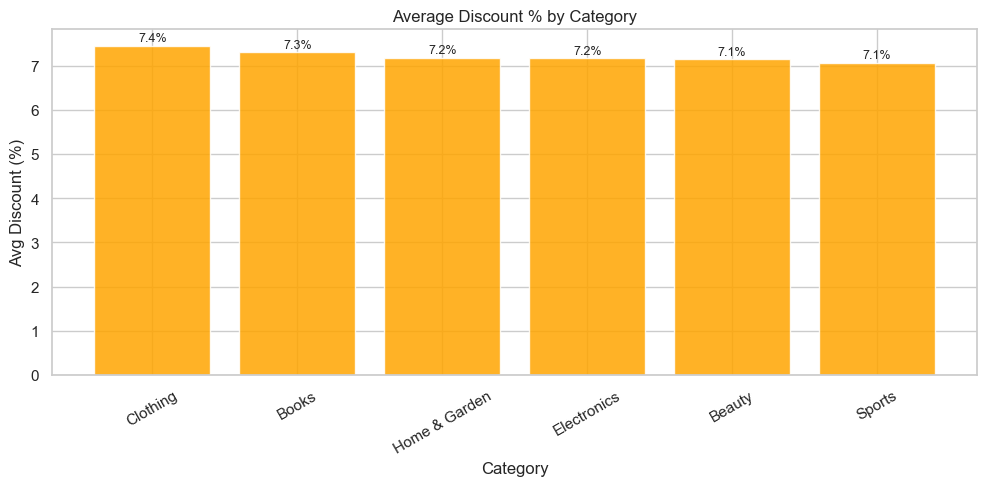

In [52]:
fig, ax = plt.subplots(figsize = (10, 5))

cat_discount = (prod_pref.groupby('category')['avg_discount'].mean().sort_values(ascending = False))
ax.bar(cat_discount.index, cat_discount.values, color = 'orange', alpha = 0.85)

ax.set_title('Average Discount % by Category')
ax.set_xlabel('Category')
ax.set_ylabel('Avg Discount (%)')
ax.tick_params(axis = 'x', rotation = 30)

# Add labels
for i, v in enumerate (cat_discount.values) :
    ax.text(i, v + 0.1, f'{v:.1f}%', ha = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

# What to observe: Which category is being discounted the most? Is discounting helping or hurting revenue?

##### Product Rating Distribution

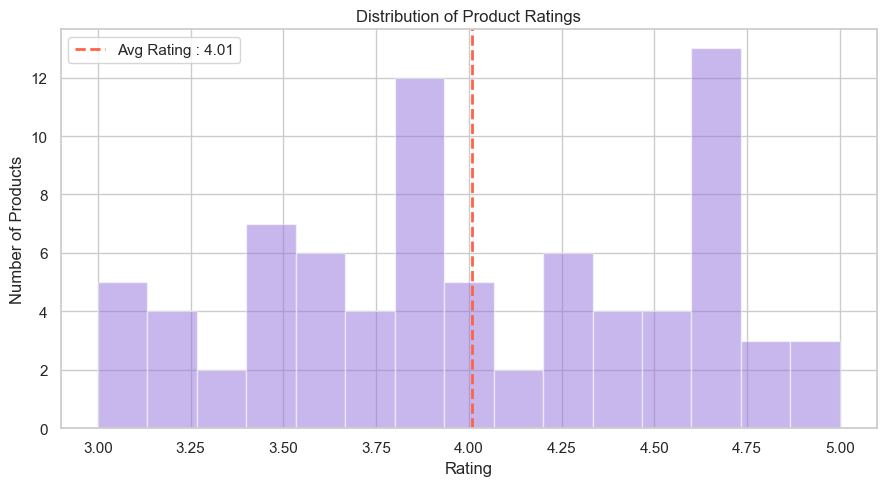

In [53]:
fig, ax = plt.subplots(figsize = (9, 5))
ax.hist(prod_pref['rating'], bins = 15, color = 'mediumpurple', edgecolor = 'white', alpha = 0.5)

ax.set_title('Distribution of Product Ratings')
ax.set_xlabel('Rating')
ax.set_ylabel('Number of Products')

# Add average line
avg_rating = prod_pref['rating'].mean()
ax.axvline(avg_rating, color = 'tomato', linestyle = '--', linewidth = 2, label = f'Avg Rating : {avg_rating:.2f}')
ax.legend()

plt.tight_layout()
plt.show()

##### Return Rate by Category

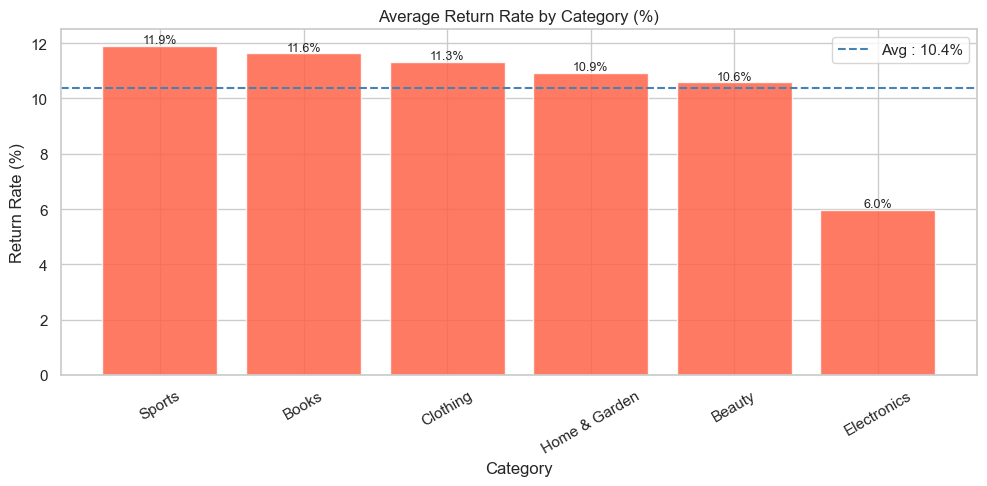

In [54]:
fig, ax = plt.subplots(figsize = (10, 5))

cat_return = (prod_pref.groupby('category')['return_rate'].mean().sort_values(ascending = False))
ax.bar(cat_return.index, cat_return.values * 100, color = 'tomato', alpha = 0.85)

ax.set_title('Average Return Rate by Category (%)')
ax.set_xlabel('Category')
ax.set_ylabel('Return Rate (%)')
ax.tick_params(axis = 'x', rotation = 30)

# Add average line
avg_rat = cat_return.mean() * 100
ax.axhline(avg_rat, color = 'steelblue', linestyle = '--', linewidth = 1.5, label = f'Avg : {avg_rat:.1f}%')
ax.legend()

for i, v in enumerate (cat_return.values) :
    ax.text(i, v * 100 + 0.1, f'{v*100:.1f}%', ha= 'center', fontsize = 9)

plt.tight_layout()
plt.show()

# High return rate = unhappy customers or misleading product listings. This is a direct hit on profitability.

##### Rating vs Return Rate Scatter

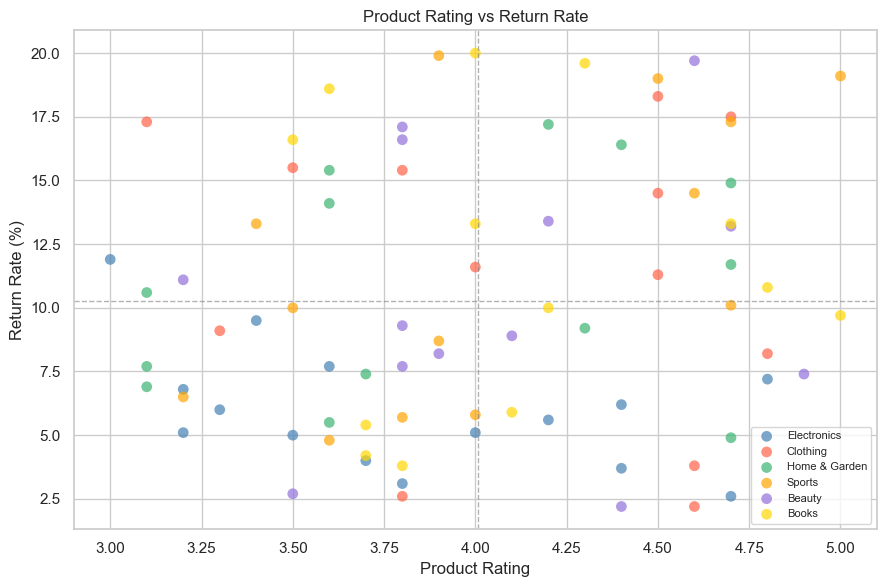

In [55]:
fig, ax = plt.subplots(figsize = (9, 6))

# Color each dot by category
categories = prod_pref['category'].unique()
colors_list = ['steelblue', 'tomato', 'mediumseagreen', 'orange', 'mediumpurple', 'gold']
color_map = dict(zip(categories, colors_list))

for cat in categories :
    subset = prod_pref[prod_pref['category'] == cat]
    ax.scatter(subset['rating'], subset['return_rate'] * 100, label = cat, color = color_map[cat], alpha = 0.7, s = 60, edgecolors = 'none')

ax.set_title('Product Rating vs Return Rate')
ax.set_xlabel('Product Rating')
ax.set_ylabel('Return Rate (%)')
ax.legend(fontsize = 8)

# Add reference lines for averages
ax.axvline(prod_pref['rating'].mean(), color = 'gray', linestyle = '--', linewidth = 1, alpha = 0.6)
ax.axhline(prod_pref['return_rate'].mean() * 100, color = 'gray', linestyle = '--', linewidth = 1, alpha = 0.6)

plt.tight_layout()
plt.show()

# What to look for: Products in the top-left (low rating + high return rate) are the most problematic. Products in the bottom-right (high rating + low return rate) are your stars.

##### Top 10 most Ordered Products

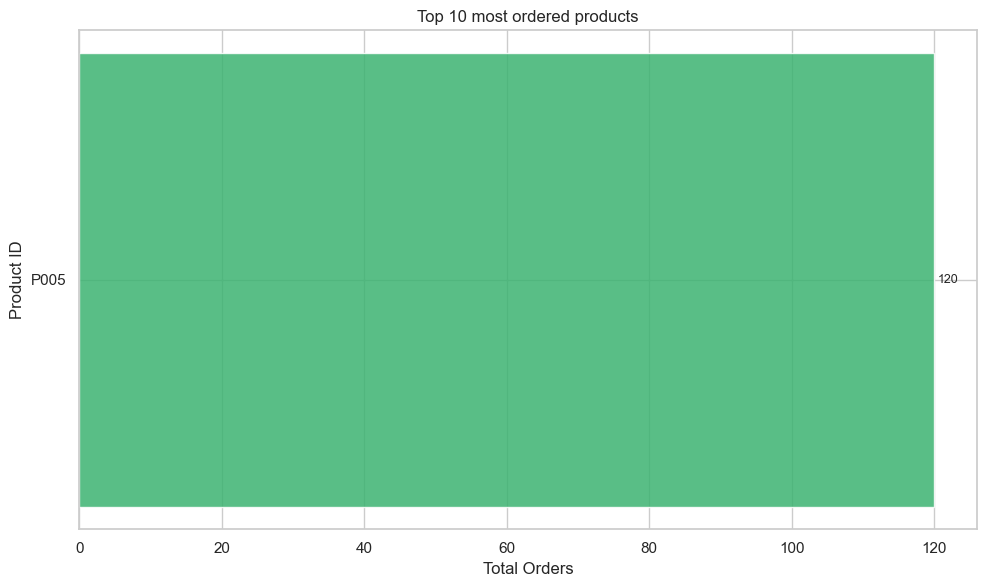

In [56]:
fig, ax = plt.subplots(figsize = (10, 6))
top10_orders = prod_pref.nlargest(1, 'total_orders')

ax.barh(top10_orders['product_id'], top10_orders['total_orders'], color = 'mediumseagreen', alpha = 0.85)

ax.set_title('Top 10 most ordered products')
ax.set_xlabel('Total Orders')
ax.set_ylabel('Product ID')

for i, v in enumerate (top10_orders['total_orders'].values) :
    ax.text(v + 0.5, i, str(v), va = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

# Compare this with the Top 10 by Revenue plot. Are the most ordered products also the highest revenue products? If not — why not?

##### Category Level Summary Table

In [57]:
cat_summary = prod_pref.groupby('category').agg(
    products       = ('product_id',    'count'),
    total_revenue  = ('total_revenue', 'sum'),
    avg_rating     = ('rating',        'mean'),
    avg_return_rate= ('return_rate',   'mean'),
    avg_discount   = ('avg_discount',  'mean')
).round(2).reset_index()

cat_summary['total_revenue'] = cat_summary['total_revenue'].round(0)
cat_summary = cat_summary.sort_values('total_revenue', ascending=False)

print("=== CATEGORY SUMMARY ===")
print(cat_summary.to_string(index=False))

=== CATEGORY SUMMARY ===
     category  products  total_revenue  avg_rating  avg_return_rate  avg_discount
  Electronics        15      1886043.0        3.81             0.06          7.17
Home & Garden        13       399782.0        3.91             0.11          7.17
       Sports        13       377806.0        4.06             0.12          7.07
     Clothing        13       213069.0        4.13             0.11          7.45
       Beauty        13       184589.0        4.05             0.11          7.15
        Books        13        61651.0        4.11             0.12          7.30


#### Customer Churn Risk Scoring

Churn means a customer has stopped buying from you.

  Signal        | Logic
- High Recency	- Hasn’t bought in a long time = risky
- Low Frequency	- Rarely orders = risky
- Low Monetary	- Spends very little = risky

##### Build the Customer table

In [58]:
# Start from delivered orders
snapshot_date = delivered['order_date'].max() + pd.Timedelta(days = 1)

churn_base = delivered.groupby('customer_id').agg(
    recency = ('order_date', lambda x : (snapshot_date - x.max()).days),
    frequency = ('order_id', 'nunique'),
    monetary = ('revenue', 'sum'),
    first_purchase = ('order_date', 'min'),
    last_purchase = ('order_date', 'max')
).reset_index()

# Customer lifespan in days
churn_base['lifespan_days'] = (
    churn_base['last_purchase'] - churn_base['first_purchase']
).dt.days

churn_base['monetary'] = churn_base['monetary'].round(2)

print("Churn Base Table Shape :", churn_base.shape)
print(churn_base.head())

Churn Base Table Shape : (1146, 7)
  customer_id  recency  frequency  monetary first_purchase last_purchase  \
0       C0001       41          4   1652.72     2023-12-23    2024-05-20   
1       C0002      329          2   1478.58     2023-02-23    2023-08-06   
2       C0003      368          1     49.18     2023-06-28    2023-06-28   
3       C0004       56          9   6167.95     2023-01-28    2024-05-05   
4       C0005      129          5   2429.03     2023-05-29    2024-02-22   

   lifespan_days  
0            149  
1            164  
2              0  
3            463  
4            269  


##### Normalize Each Feature to 0-1 Scale

In [59]:
# We need all features on the same scale before scoring

def normalize (series) :
    return (series - series.min()) / (series.max() - series.min() + 1e-9)

# High recency = bad (customer hasn't bought recently)
churn_base['r_score'] = normalize(churn_base['recency'])

# Low frequency = bad, so we flip it
churn_base['f_score'] = 1 - normalize(churn_base['frequency'])

# Low monetary = bad, so we flip it
churn_base['m_score'] = 1 - normalize(churn_base['monetary'])

print("Normalized scores added!")
print(churn_base[['customer_id', 'r_score', 'f_score', 'm_score']].head())

# Why normalize? Recency is in days (0–500), frequency is in orders (1–20), monetary is in dollars (0–10,000). Without normalization, monetary would dominate the score unfairly.

Normalized scores added!
  customer_id   r_score   f_score   m_score
0       C0001  0.073801  0.869565  0.900914
1       C0002  0.605166  0.956522  0.911424
2       C0003  0.677122  1.000000  0.997694
3       C0004  0.101476  0.652174  0.628402
4       C0005  0.236162  0.826087  0.854061


##### Calculate Final Churn Risk Score

In [60]:
# Weighted formula - recency matters most
# R = 45%, F = 35%, M = 20%

churn_base['churn_score'] = (
    0.45 * churn_base['r_score'] + 0.35 * churn_base['f_score'] + 0.20 * churn_base['m_score']
).round(4)

print("Churn Score Range :")
print(f"Min : {churn_base['churn_score'].min():.4f}")
print(f"Max : {churn_base['churn_score'].max():.4f}")
print(f"Avg : {churn_base['churn_score'].mean():.4f}")

# Score closer to 1 = high churn risk. Score closer to 0 = low churn risk.

Churn Score Range :
Min : 0.0961
Max : 0.9979
Avg : 0.5375


##### Assign Risk Tiers

In [61]:
churn_base['risk_tier'] = pd.cut(churn_base['churn_score'], bins = [0, 0.33, 0.60, 1.0], labels = ['Low Risk', 'Medium Risk', 'High Risk'])

print("\nRisk Tier Distribution:")
print(churn_base['risk_tier'].value_counts())


Risk Tier Distribution:
risk_tier
Medium Risk    690
High Risk      351
Low Risk       105
Name: count, dtype: int64


##### Risk Tier Summary Table

In [62]:
tier_summary = churn_base.groupby('risk_tier', observed = True).agg(
    customer_count = ('customer_id', 'count'),
    avg_recency = ('recency', 'mean'),
    avg_frequency = ('frequency', 'mean'),
    avg_spend = ('monetary', 'mean'),
    total_revenue = ('monetary', 'sum')
).round(1).reset_index()

print("\n===Churn Risk Tier Summary===")
print(tier_summary.to_string(index = False))


===Churn Risk Tier Summary===
  risk_tier  customer_count  avg_recency  avg_frequency  avg_spend  total_revenue
   Low Risk             105         21.0           15.5     7565.5       794380.7
Medium Risk             690         55.1            6.2     2861.0      1974077.7
  High Risk             351        262.6            2.4     1009.9       354481.9


##### Customer Count by Risk Tier

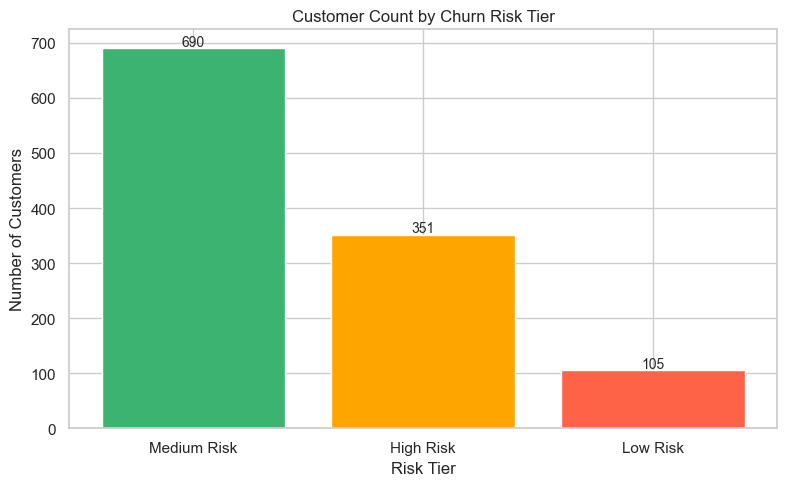

In [63]:
fig, ax = plt.subplots(figsize = (8, 5))
tier_cnt = churn_base['risk_tier'].value_counts()

ax.bar(tier_cnt.index, tier_cnt.values, color = ['mediumseagreen', 'orange', 'tomato'])

ax.set_title('Customer Count by Churn Risk Tier')
ax.set_xlabel('Risk Tier')
ax.set_ylabel('Number of Customers')

for i, v in enumerate (tier_cnt.values) :
    ax.text(i, v + 5, str(v), ha = 'center', fontsize = 10)

plt.tight_layout()
plt.show()

##### Churn Score Distribution

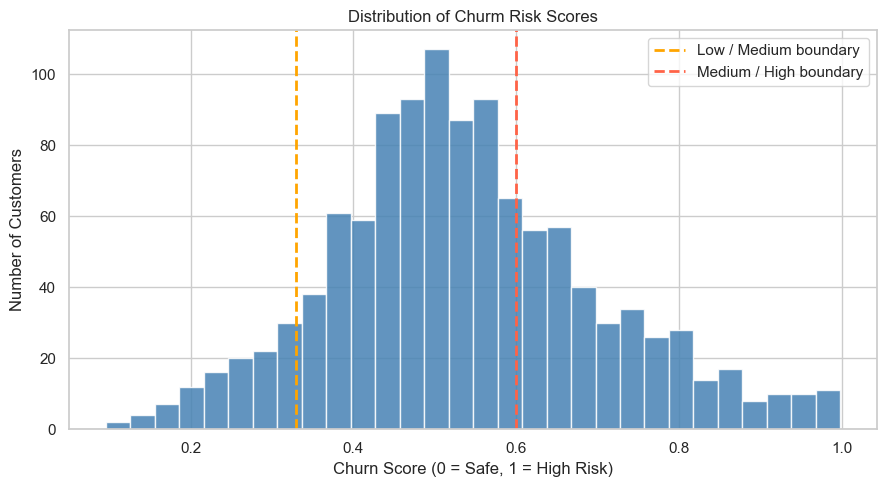

In [64]:
fig, ax = plt.subplots(figsize = (9, 5))

ax.hist(churn_base['churn_score'], bins = 30, color = 'steelblue', edgecolor = 'white', alpha = 0.85)

ax.set_title('Distribution of Churm Risk Scores')
ax.set_xlabel('Churn Score (0 = Safe, 1 = High Risk)')
ax.set_ylabel('Number of Customers')

# Mark the tier boundaries
ax.axvline(0.33, color = 'orange', linestyle = '--', linewidth = 2, label = 'Low / Medium boundary')
ax.axvline(0.60, color = 'tomato', linestyle = '--', linewidth = 2, label = 'Medium / High boundary')
ax.legend()

plt.tight_layout()
plt.show()

# What to observe: Where do most customers fall? A spike near 1.0 means a large portion of your base is at high churn risk.

##### Revenue at Risk by Tier

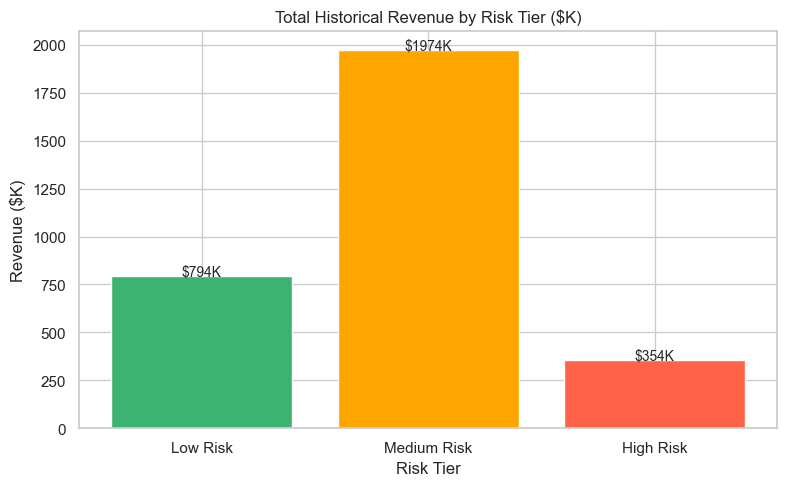

In [65]:
fig, ax = plt.subplots(figsize = (8, 5))
tier_rev = churn_base.groupby('risk_tier', observed = True)['monetary'].sum()

ax.bar(tier_rev.index, tier_rev.values / 1000, color = ['mediumseagreen', 'orange', 'tomato'])

ax.set_title('Total Historical Revenue by Risk Tier ($K)')
ax.set_xlabel('Risk Tier')
ax.set_ylabel('Revenue ($K)')

for i, v in enumerate (tier_rev.values) :
    ax.text(i, v / 1000 + 2, f'${v/1000:.0f}K', ha = 'center', fontsize = 10)

plt.tight_layout()
plt.show()

# This is the most impactful chart for a business. It shows exactly how much revenue is at risk if high-risk customers churn completely.

##### Recency vs Monetary Scatter by Risk Tier

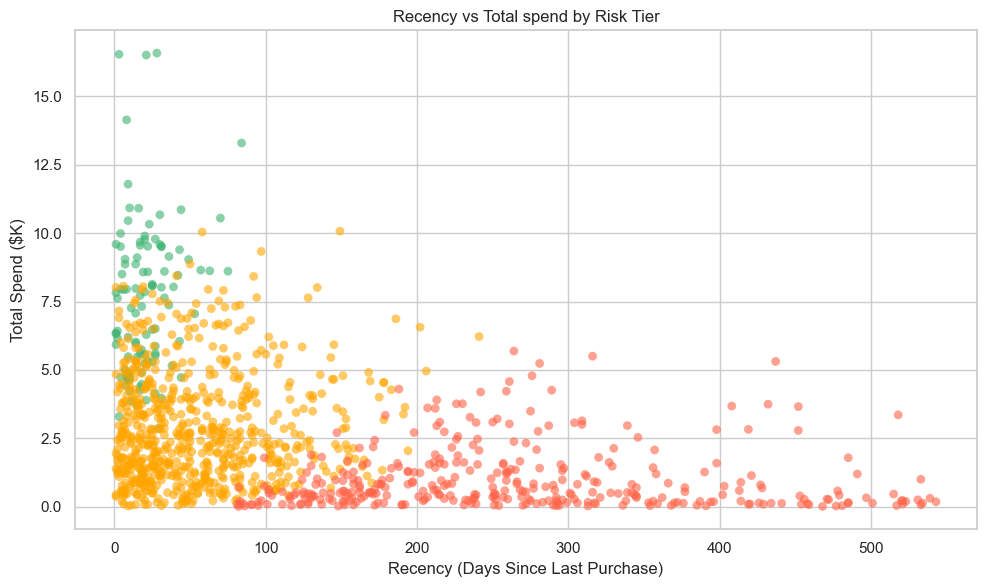

In [66]:
fig, ax = plt.subplots(figsize = (10, 6))

colors_map = {
    'Low Risk' : 'mediumseagreen',
    'Medium Risk' : 'orange',
    'High Risk' : 'tomato'
}

for tier, grp in churn_base.groupby('risk_tier', observed = True) :
    ax.scatter(grp['recency'], grp['monetary'] / 1000, label = tier, color = colors_map[tier], alpha = 0.6, s = 40, edgecolors = 'none')

ax.set_title('Recency vs Total spend by Risk Tier')
ax.set_xlabel('Recency (Days Since Last Purchase)')
ax.set_ylabel('Total Spend ($K)')

plt.tight_layout()
plt.show()

# What to observe: High risk customers (red) should cluster on the right side - high recency (haven’t bought in a long time) and low spend.

##### Avg Recency and Frequency by Tier

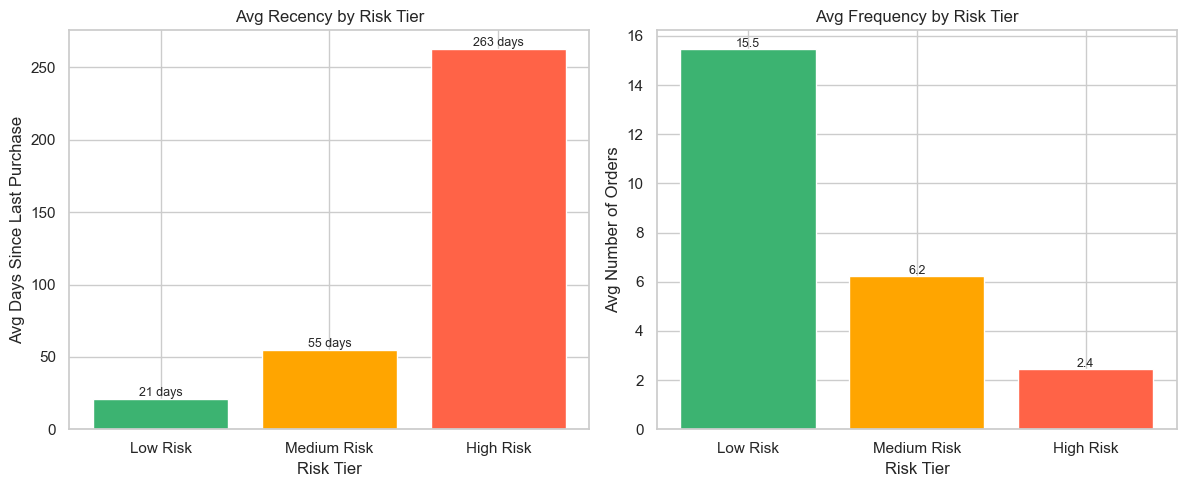

In [67]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

# Avg Recency
tier_rec = churn_base.groupby('risk_tier', observed = True)['recency'].mean()
axes[0].bar(tier_rec.index, tier_rec.values, color = ['mediumseagreen', 'orange', 'tomato'])
axes[0].set_title('Avg Recency by Risk Tier')
axes[0].set_xlabel('Risk Tier')
axes[0].set_ylabel('Avg Days Since Last Purchase')

for i, v in enumerate(tier_rec.values) :
    axes[0].text(i, v + 2, f'{v:.0f} days', ha = 'center', fontsize = 9)

# Avg Frequency
tier_freq = churn_base.groupby('risk_tier', observed = True)['frequency'].mean()
axes[1].bar(tier_freq.index, tier_freq.values, color = ['mediumseagreen', 'orange', 'tomato'])
axes[1].set_title('Avg Frequency by Risk Tier')
axes[1].set_xlabel('Risk Tier')
axes[1].set_ylabel('Avg Number of Orders')
for i, v in enumerate (tier_freq.values) :
    axes[1].text(i, v + 0.1, f'{v:.1f}', ha = 'center', fontsize = 9)

plt.tight_layout()
plt.show()

##### Export High Risk Customers

In [68]:
# Save the high risk customers to a CSV
# This is what you'd hand over to a marketing team in real life
high_risk = churn_base[churn_base['risk_tier'] == 'High Risk'].copy()
high_risk = high_risk.sort_values('churn_score', ascending=False)

high_risk.to_csv('high_risk_customers.csv', index=False)

print(f"High Risk Customers : {len(high_risk)}")
print(f"Revenue at Risk     : ${high_risk['monetary'].sum():,.2f}")
print(f"\nTop 10 Highest Risk Customers:")
print(high_risk[['customer_id', 'recency', 'frequency',
                  'monetary', 'churn_score']].head(10).to_string(index=False))

# Exporting the list is what makes this analysis actionable. A marketing team can now run a win-back campaign targeting exactly these customers.

High Risk Customers : 351
Revenue at Risk     : $354,481.91

Top 10 Highest Risk Customers:
customer_id  recency  frequency  monetary  churn_score
      C0612      543          1    183.82       0.9979
      C0767      539          1    310.64       0.9931
      C0336      534          1    135.39       0.9910
      C0924      533          1     71.79       0.9910
      C0593      531          1    253.29       0.9871
      C1040      523          1    195.02       0.9812
      C0432      521          1     97.75       0.9807
      C0199      533          1   1004.97       0.9797
      C0231      521          1    228.80       0.9791
      C0874      517          1     45.18       0.9780


#### Final Business Summary

In [69]:
print("=" * 50)
print("   SHOPSENSE — FINAL PROJECT SUMMARY")
print("=" * 50)

total_customers = churn_base['customer_id'].nunique()
high_risk_count = len(churn_base[churn_base['risk_tier'] == 'High Risk'])
high_risk_rev   = churn_base[churn_base['risk_tier'] == 'High Risk']['monetary'].sum()
total_rev       = delivered['revenue'].sum()

print(f"\nTotal Customers Analysed : {total_customers:,}")
print(f"Total Revenue            : ${total_rev:,.2f}")
print(f"\nHigh Risk Customers      : {high_risk_count:,}")
print(f"Revenue at Risk          : ${high_risk_rev:,.2f}")
print(f"% Revenue at Risk        : {high_risk_rev/total_rev*100:.1f}%")

print("\n--- Recommended Actions ---")
print("1. Run win-back email campaign for High Risk customers")
print("2. Offer personalised discount to Medium Risk customers")
print("3. Reward Low Risk customers with a loyalty programme")
print("4. Focus acquisition on age groups with highest AOV")
print("5. Review high return-rate products in Product Analysis")

   SHOPSENSE — FINAL PROJECT SUMMARY

Total Customers Analysed : 1,146
Total Revenue            : $3,122,940.34

High Risk Customers      : 351
Revenue at Risk          : $354,481.91
% Revenue at Risk        : 11.4%

--- Recommended Actions ---
1. Run win-back email campaign for High Risk customers
2. Offer personalised discount to Medium Risk customers
3. Reward Low Risk customers with a loyalty programme
4. Focus acquisition on age groups with highest AOV
5. Review high return-rate products in Product Analysis
